# TFG. Clasificación de tumores pulmonares en CT con explicabilidad

Cuaderno del estudio piloto del Trabajo Fin de Grado *Clasificación de tumores pulmonares usando
modelos de machine learning y deep learning* (Jorge Monzó Satorre, Universidad de Alicante, 2026).

**Dataset.** *Chest CT-Scan Images* (M. Hany), Kaggle `mohamedhanyyy/chest-ctscan-images`, con cuatro
clases (`adenocarcinoma`, `large.cell.carcinoma`, `squamous.cell.carcinoma` y `normal`).

**Objetivo.** Probar el pipeline completo sobre un subconjunto reducido (máximo de 75 imágenes por
clase) para validar la metodología y analizar la calidad del dataset, como se describe en la
memoria.

| Bloque | Contenido | Memoria |
|---|---|---|
| 0 | Configuración y reproducibilidad | 4.6 |
| 1 | Descripción, origen y deduplicación del dataset | 4.2.1 |
| 2 | Análisis exploratorio y distribución de clases | 4.2.2 |
| 3 | Preprocesado, particionado y control E0 | 4.2.3 y 5.3.1 |
| 4 | Aumentación de datos | 4.2.4 |
| 5 | Arquitectura de los modelos | 4.3 |
| 6 | Entrenamiento y comparativa inicial (E1) | 4.4.1 y 5.3.2 |
| 7 | Validación cruzada (E2) y evaluación en test (E3) | 4.4.2, 5.3.3 y 5.3.4 |
| 8 | Explicabilidad con Grad-CAM y LIME (E4) | 4.5 y 5.4 |
| 9 | Registro de resultados | |

---
## Bloque 0 — Configuración y reproducibilidad

In [ ]:
!pip install -q kagglehub lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 10.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
import os, hashlib, random, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ---------------- Reproducibilidad ----------------
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---------------- Hiperparametros del piloto ----------------
IMG_SIZE        = (224, 224)   # entrada estandar de las redes preentrenadas en ImageNet
BATCH_SIZE      = 16           # pequeno: el dataset piloto lo es
N_POR_CLASE     = 75           # -> 300 imagenes en total
TEST_FRAC       = 0.15         # conjunto de test bloqueado, no se toca hasta el final
VAL_FRAC        = 0.15         # validacion dentro del trainval (para la comparativa inicial)
EPOCHS_CABEZA   = 30
EPOCHS_FINETUNE = 20
N_FOLDS         = 5
DEDUP_PERCEPTUAL = True        # elimina near-duplicates ademas de copias exactas
USAR_FLIP_HORIZONTAL = False   # ver justificacion en el Bloque 4

print("TensorFlow:", tf.__version__)
print("Keras      :", keras.__version__)
print("GPU        :", tf.config.list_physical_devices("GPU") or "NO DISPONIBLE (sera lento)")

TensorFlow: 2.20.0
Keras      : 3.13.2
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
## Bloque 1 — 4.2.1 Descripción y origen del dataset

El dataset original viene dividido en `train`, `valid` y `test`, pero las carpetas de `train`
incluyen el estadiaje TNM en el nombre (p. ej. `adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib`) y las
de `test` no. Las etiquetas se normalizan por prefijo.

Las tres particiones originales se reúnen en un único conjunto, que se deduplica y se vuelve a
dividir de forma estratificada. Al haber duplicados repartidos entre las carpetas
originales (613/72/315), esa partición no garantiza la ausencia de fugas de datos.

In [ ]:
import kagglehub

RUTA_BASE = Path(kagglehub.dataset_download("mohamedhanyyy/chest-ctscan-images"))
print("Descargado en:", RUTA_BASE)

# La estructura real puede variar: buscamos recursivamente las carpetas train/valid/test
carpetas_split = [p for p in RUTA_BASE.rglob("*") if p.is_dir() and p.name in ("train", "valid", "test")]
print("\nParticiones encontradas:")
for c in carpetas_split:
    print("  -", c.relative_to(RUTA_BASE))

Using Colab cache for faster access to the 'chest-ctscan-images' dataset.
Descargado en: /kaggle/input/chest-ctscan-images

Particiones encontradas:
  - Data/valid
  - Data/test
  - Data/train


In [ ]:
def normalizar_clase(nombre_carpeta: str):
    # Mapea el nombre bruto de carpeta a una de las 4 clases canonicas.
    n = nombre_carpeta.lower().strip()
    if n.startswith("adenocarcinoma"):
        return "adenocarcinoma"
    if n.startswith("large.cell.carcinoma") or n.startswith("large_cell"):
        return "large.cell.carcinoma"
    if n.startswith("squamous.cell.carcinoma") or n.startswith("squamous_cell"):
        return "squamous.cell.carcinoma"
    if n.startswith("normal"):
        return "normal"
    return None

EXTENSIONES = {".png", ".jpg", ".jpeg"}
registros = []

for split in carpetas_split:
    for carpeta_clase in sorted(split.iterdir()):
        if not carpeta_clase.is_dir():
            continue
        clase = normalizar_clase(carpeta_clase.name)
        if clase is None:
            print("  [aviso] carpeta no reconocida:", carpeta_clase.name)
            continue
        for f in carpeta_clase.iterdir():
            if f.suffix.lower() in EXTENSIONES:
                registros.append({
                    "ruta": str(f),
                    "clase": clase,
                    "split_original": split.name,
                    "carpeta_bruta": carpeta_clase.name,
                })

df_completo = pd.DataFrame(registros)
print("Imagenes totales encontradas:", len(df_completo))
print()
print(pd.crosstab(df_completo["clase"], df_completo["split_original"], margins=True))

Imagenes totales encontradas: 1000

split_original           test  train  valid   All
clase                                            
adenocarcinoma            120    195     23   338
large.cell.carcinoma       51    115     21   187
normal                     54    148     13   215
squamous.cell.carcinoma    90    155     15   260
All                       315    613     72  1000


### Deduplicación

Dos niveles de comprobación.

1. **Hash MD5 de los bytes del fichero**, que detecta las copias exactas (los ficheros `... - Copy.png`).
2. **Average hash de 16×16**, que detecta la misma imagen guardada de nuevo, reescalada o recomprimida.

Dos imágenes se consideran duplicadas cuando coincide su MD5 o su *average hash*. De cada grupo se
conserva la primera imagen en el orden de lectura. Sin este paso, el mismo corte de CT podría acabar
a la vez en entrenamiento y en test e inflar las métricas.

In [ ]:
def md5_fichero(ruta, bloque=1 << 20):
    h = hashlib.md5()
    with open(ruta, "rb") as fh:
        for chunk in iter(lambda: fh.read(bloque), b""):
            h.update(chunk)
    return h.hexdigest()

def average_hash(ruta, lado=16):
    # Average hash: reduce a escala de grises lado x lado y binariza respecto a la media.
    with Image.open(ruta) as im:
        im = im.convert("L").resize((lado, lado), Image.BILINEAR)
        a = np.asarray(im, dtype=np.float32)
    bits = (a > a.mean()).astype(np.uint8).flatten()
    return bits.tobytes().hex()

n_inicial = len(df_completo)

df_completo["md5"] = df_completo["ruta"].apply(md5_fichero)
df_dedup = df_completo.drop_duplicates(subset="md5", keep="first").copy()
n_tras_md5 = len(df_dedup)

if DEDUP_PERCEPTUAL:
    df_dedup["ahash"] = df_dedup["ruta"].apply(average_hash)
    df_dedup = df_dedup.drop_duplicates(subset="ahash", keep="first").copy()

n_final = len(df_dedup)

print(f"Imagenes iniciales          : {n_inicial}")
print(f"Tras eliminar copias exactas: {n_tras_md5}  (-{n_inicial - n_tras_md5})")
print(f"Tras near-duplicates        : {n_final}  (-{n_tras_md5 - n_final})")
print(f"Reduccion total             : {100 * (n_inicial - n_final) / n_inicial:.1f}%")
print()
print(df_dedup["clase"].value_counts())

Imagenes iniciales          : 1000
Tras eliminar copias exactas: 847  (-153)
Tras near-duplicates        : 825  (-22)
Reduccion total             : 17.5%

clase
adenocarcinoma             336
squamous.cell.carcinoma    257
large.cell.carcinoma       186
normal                      46
Name: count, dtype: int64


**Diagnóstico de duplicados por clase y entre las particiones originales.**

Se cuenta cuántas imágenes de cada partición original tienen una copia en otra partición.

In [ ]:
# ---- Diagnostico de duplicados: por clase y entre particiones originales ----
diag = []
for clase, g in df_completo.groupby("clase"):
    diag.append({
        "clase": clase,
        "n_original": len(g),
        "n_unicas": g["md5"].nunique(),
        "n_duplicadas": len(g) - g["md5"].nunique(),
        "pct_duplicadas": 100 * (len(g) - g["md5"].nunique()) / len(g),
        "copias_max": g["md5"].value_counts().max(),
    })
df_diag = pd.DataFrame(diag).sort_values("pct_duplicadas", ascending=False)
print(df_diag.to_string(index=False, float_format=lambda v: f"{v:.1f}"))

# ---- Fuga entre particiones originales ----
grupos = df_completo.groupby("md5").agg(
    clase=("clase", "first"),
    splits=("split_original", lambda s: frozenset(s)),
    n_copias=("ruta", "size"),
)
cruz = grupos[grupos["splits"].apply(len) > 1]
train_test = grupos[grupos["splits"].apply(lambda s: {"train", "test"} <= set(s))]

print(f"\nGrupos de imagenes identicas presentes en >1 particion original: {len(cruz)}")
print(f"De ellos, presentes simultaneamente en train Y test: {len(train_test)}")
if len(cruz):
    print("\nPor clase:")
    print(cruz.groupby("clase").size().to_string())

# Cuantas imagenes del test original son copia de alguna del train original
md5_train = set(df_completo[df_completo.split_original == "train"]["md5"])
test_orig = df_completo[df_completo.split_original == "test"]
n_fuga = test_orig["md5"].isin(md5_train).sum()
print(f"\nImagenes del test original que ya aparecen en train: "
      f"{n_fuga}/{len(test_orig)} ({100*n_fuga/len(test_orig):.1f}%)")
print(test_orig[test_orig["md5"].isin(md5_train)]["clase"].value_counts().to_string())

                  clase  n_original  n_unicas  n_duplicadas  pct_duplicadas  copias_max
                 normal         215        66           149            69.3          10
squamous.cell.carcinoma         260       258             2             0.8           2
         adenocarcinoma         338       337             1             0.3           2
   large.cell.carcinoma         187       187             0             0.0           1

Grupos de imagenes identicas presentes en >1 particion original: 22
De ellos, presentes simultaneamente en train Y test: 19

Por clase:
clase
normal    22

Imagenes del test original que ya aparecen en train: 46/315 (14.6%)
clase
normal    46


**Inspección visual de los casi duplicados.**

El filtro MD5 deja 66 imágenes únicas de la clase `normal` y el *average hash* las reduce a 46, de
modo que 20 de las 22 eliminaciones perceptuales caen en esa clase. Para descartar que el *hash*
esté fusionando cortes distintos pero parecidos, se muestran los grupos eliminados.

Grupos de near-duplicates: 16 (38 imagenes implicadas)
clase
adenocarcinoma           2
large.cell.carcinoma     2
normal                  34


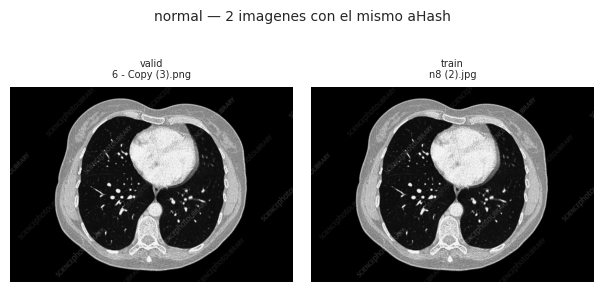

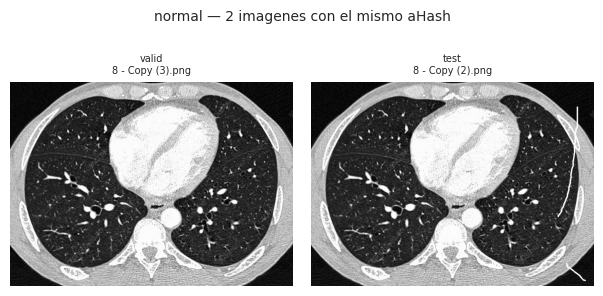

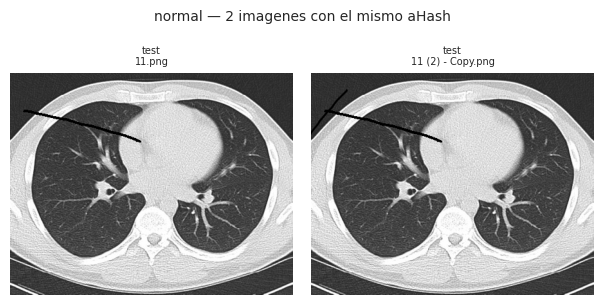

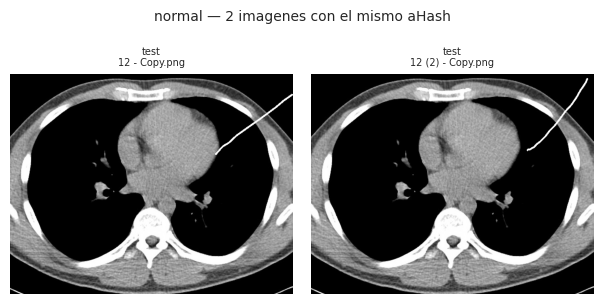

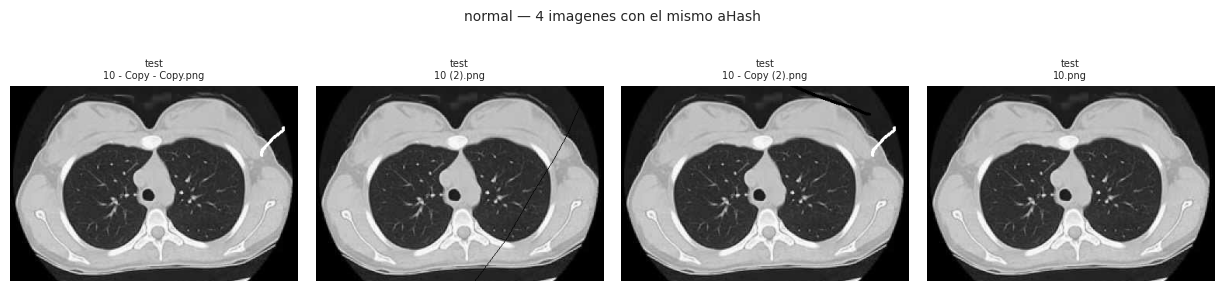

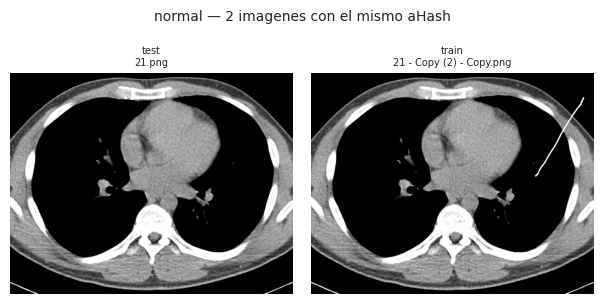

In [ ]:
# ---- Inspeccion visual de los near-duplicates eliminados por aHash ----
tmp = df_completo.drop_duplicates(subset="md5", keep="first").copy()
tmp["ahash"] = tmp["ruta"].apply(average_hash)

grupos_ah = tmp.groupby("ahash").filter(lambda g: len(g) > 1)
print(f"Grupos de near-duplicates: {grupos_ah['ahash'].nunique()} "
      f"({len(grupos_ah)} imagenes implicadas)")
print(grupos_ah.groupby("clase").size().to_string())

# Mostrar hasta 6 grupos para juzgar a ojo si son realmente la misma imagen
claves = grupos_ah["ahash"].unique()[:6]
for k in claves:
    g = grupos_ah[grupos_ah["ahash"] == k]
    fig, axes = plt.subplots(1, len(g), figsize=(3.1 * len(g), 3.3))
    axes = np.atleast_1d(axes)
    for ax, (_, fila) in zip(axes, g.iterrows()):
        with Image.open(fila["ruta"]) as im:
            ax.imshow(im.convert("RGB"))
        ax.axis("off")
        ax.set_title(f"{fila['split_original']}\n{Path(fila['ruta']).name[:24]}", fontsize=7)
    plt.suptitle(f"{g.iloc[0]['clase']} — {len(g)} imagenes con el mismo aHash", fontsize=10)
    plt.tight_layout(); plt.show()

Proporcion de imagenes con borde oscuro (fondo de aire):
clase
adenocarcinoma             90.2
large.cell.carcinoma       93.5
normal                     26.1
squamous.cell.carcinoma    94.9

Mediana de intensidad del borde:
clase
adenocarcinoma              3.5
large.cell.carcinoma        4.5
normal                     67.5
squamous.cell.carcinoma     1.0


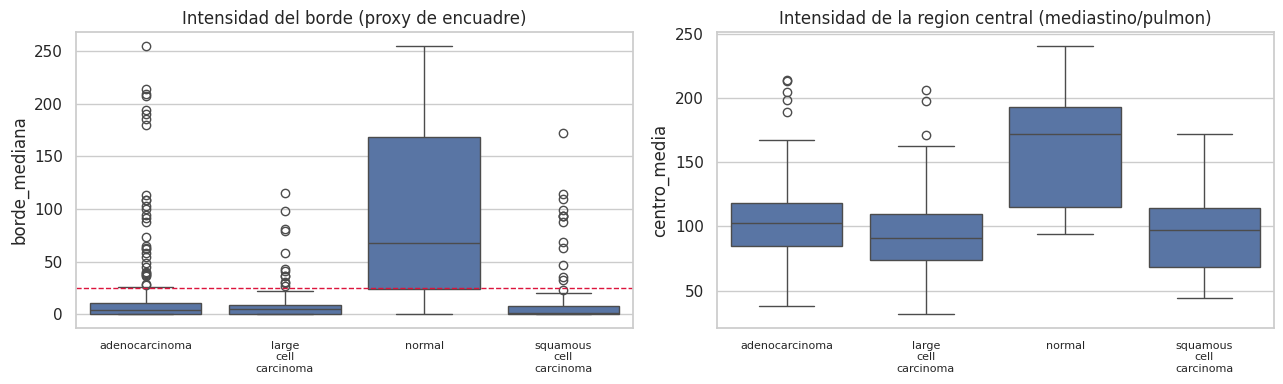

In [ ]:
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns


# ---- Diferencias de encuadre/adquisicion entre clases (sin descartar imagenes) ----
def stats_borde(ruta, ancho=20):
    with Image.open(ruta) as im:
        a = np.asarray(im.convert("L").resize((256, 256)), dtype=np.float32)
    borde = np.concatenate([a[:ancho, :].ravel(), a[-ancho:, :].ravel(),
                            a[:, :ancho].ravel(), a[:, -ancho:].ravel()])
    return pd.Series({"borde_mediana": float(np.median(borde)),
                      "borde_media": float(borde.mean()),
                      "centro_media": float(a[96:160, 96:160].mean())})

# Estadisticos de borde y region central, asignados directamente para no duplicar columnas
stats_results = df_dedup["ruta"].apply(stats_borde)
df_dedup[['borde_mediana', 'borde_media', 'centro_media']] = stats_results
df_dedup["borde_oscuro"] = df_dedup["borde_mediana"] < 25

# CLASES se define aqui porque la necesitan las figuras de esta celda
CLASES = sorted(df_dedup["clase"].unique())

print("Proporcion de imagenes con borde oscuro (fondo de aire):")
print((df_dedup.groupby("clase")["borde_oscuro"].mean() * 100)
      .round(1).to_string())
print("\nMediana de intensidad del borde:")
print(df_dedup.groupby("clase")["borde_mediana"].median().round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df_dedup, x="clase", y="borde_mediana", ax=axes[0])
axes[0].axhline(25, color="crimson", ls="--", lw=1)
axes[0].set_title("Intensidad del borde (proxy de encuadre)")
sns.boxplot(data=df_dedup, x="clase", y="centro_media", ax=axes[1])
axes[1].set_title("Intensidad de la region central (mediastino/pulmon)")
for ax in axes:
    ax.set_xticklabels([c.replace(".", "\n") for c in CLASES], fontsize=8)
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

### Submuestreo estratificado

Se fija un máximo de `N_POR_CLASE` imágenes por clase con semilla. La clase `normal` solo dispone
de 46 imágenes únicas tras la deduplicación, de modo que el subconjunto piloto tiene 271 imágenes
(75+75+75+46) y queda aproximadamente balanceado.

In [ ]:
def submuestrear(df, n_por_clase, seed=SEED):
    partes = []
    for clase, grupo in df.groupby("clase"):
        n = min(n_por_clase, len(grupo))
        if n < n_por_clase:
            print(f"  [aviso] '{clase}' solo tiene {len(grupo)} imagenes disponibles")
        partes.append(grupo.sample(n=n, random_state=seed))
    return pd.concat(partes).sample(frac=1.0, random_state=seed).reset_index(drop=True)

df = submuestrear(df_dedup, N_POR_CLASE)

CLASES = sorted(df["clase"].unique())
CLASE_A_IDX = {c: i for i, c in enumerate(CLASES)}
df["y"] = df["clase"].map(CLASE_A_IDX)
N_CLASES = len(CLASES)

print("Dataset piloto:", len(df), "imagenes |", N_CLASES, "clases")
print(CLASES)
print()
print(df["clase"].value_counts())

  [aviso] 'normal' solo tiene 46 imagenes disponibles
Dataset piloto: 271 imagenes | 4 clases
['adenocarcinoma', 'large.cell.carcinoma', 'normal', 'squamous.cell.carcinoma']

clase
adenocarcinoma             75
large.cell.carcinoma       75
squamous.cell.carcinoma    75
normal                     46
Name: count, dtype: int64


---
## Bloque 2 — 4.2.2 Análisis exploratorio y distribución de clases

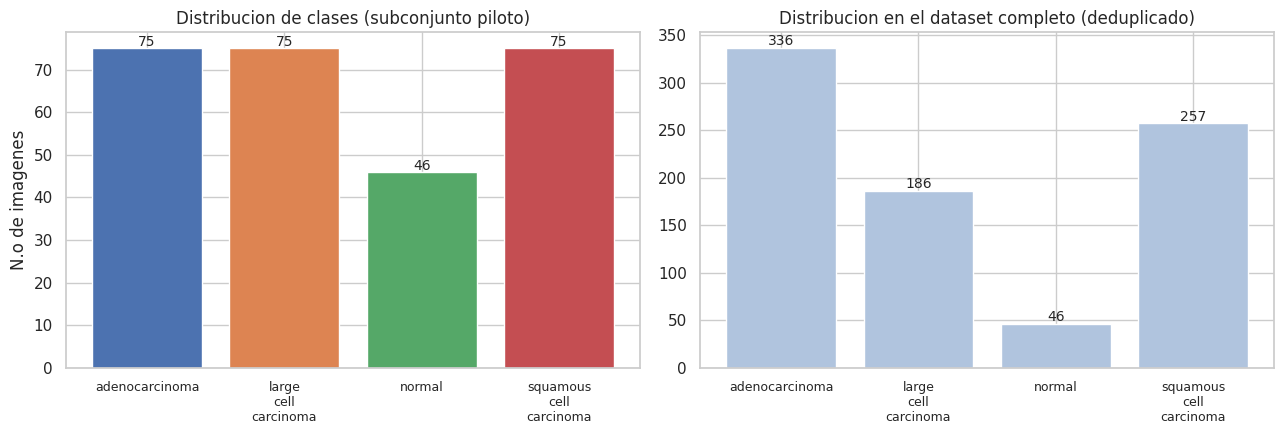

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

conteo = df["clase"].value_counts().reindex(CLASES)
axes[0].bar(range(N_CLASES), conteo.values, color=sns.color_palette("deep", N_CLASES))
axes[0].set_xticks(range(N_CLASES))
axes[0].set_xticklabels([c.replace(".", "\n") for c in CLASES], fontsize=9)
axes[0].set_ylabel("N.o de imagenes")
axes[0].set_title("Distribucion de clases (subconjunto piloto)")
for i, v in enumerate(conteo.values):
    axes[0].text(i, v + 0.5, str(v), ha="center", fontsize=10)

conteo_orig = df_dedup["clase"].value_counts().reindex(CLASES)
axes[1].bar(range(N_CLASES), conteo_orig.values, color="lightsteelblue")
axes[1].set_xticks(range(N_CLASES))
axes[1].set_xticklabels([c.replace(".", "\n") for c in CLASES], fontsize=9)
axes[1].set_title("Distribucion en el dataset completo (deduplicado)")
for i, v in enumerate(conteo_orig.values):
    axes[1].text(i, v + 3, str(v), ha="center", fontsize=10)

plt.tight_layout(); plt.show()

Resoluciones distintas presentes: 262
ancho  alto
512    512     3
800    577     2
438    338     2
619    481     2
450    329     2
441    341     2
393    270     2
847    533     2
dtype: int64

Modos de color: {'RGBA': 254, 'RGB': 17}


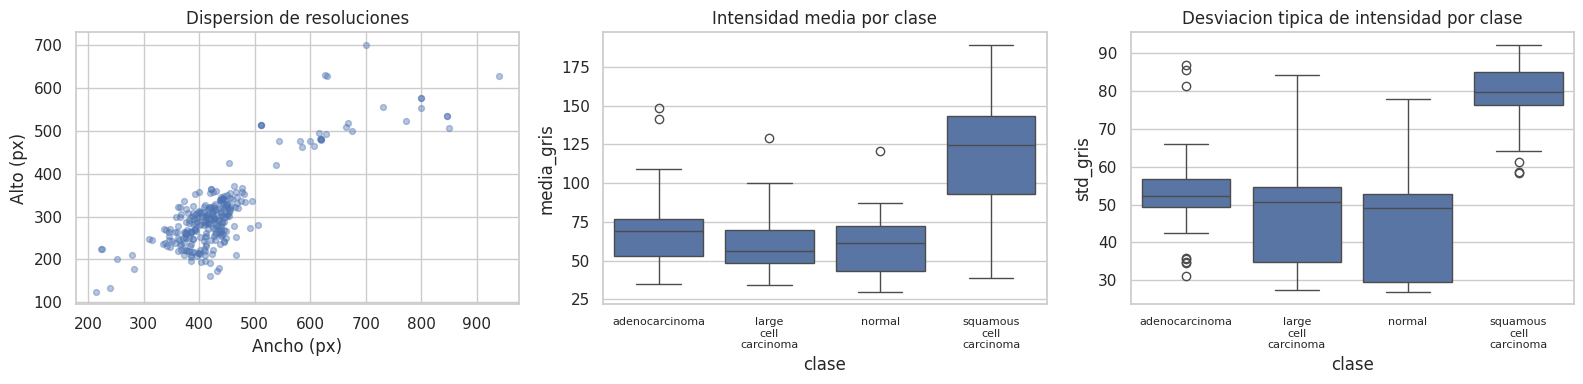

In [ ]:
# Propiedades tecnicas de las imagenes: heterogeneidad de resolucion y de intensidad
props = []
for _, fila in df.iterrows():
    with Image.open(fila["ruta"]) as im:
        w, h = im.size
        modo = im.mode
        arr = np.asarray(im.convert("L"), dtype=np.float32)
    props.append({"clase": fila["clase"], "ancho": w, "alto": h, "modo": modo,
                  "media_gris": arr.mean(), "std_gris": arr.std()})

df_props = pd.DataFrame(props)

print("Resoluciones distintas presentes:", df_props.groupby(["ancho", "alto"]).size().shape[0])
print(df_props.groupby(["ancho", "alto"]).size().sort_values(ascending=False).head(8))
print("\nModos de color:", df_props["modo"].value_counts().to_dict())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(df_props["ancho"], df_props["alto"], alpha=0.4, s=18)
axes[0].set_xlabel("Ancho (px)"); axes[0].set_ylabel("Alto (px)")
axes[0].set_title("Dispersion de resoluciones")

sns.boxplot(data=df_props, x="clase", y="media_gris", ax=axes[1])
axes[1].set_xticklabels([c.replace(".", "\n") for c in CLASES], fontsize=8)
axes[1].set_title("Intensidad media por clase")

sns.boxplot(data=df_props, x="clase", y="std_gris", ax=axes[2])
axes[2].set_xticklabels([c.replace(".", "\n") for c in CLASES], fontsize=8)
axes[2].set_title("Desviacion tipica de intensidad por clase")

plt.tight_layout(); plt.show()

Se comprueba si las clases se separan solo por resolución, modo de color o intensidad. Si es así,
existe el riesgo de que el modelo aprenda un **atajo de adquisición** (protocolo del escáner,
ventana de visualización u hospital de origen) en lugar de la patología.

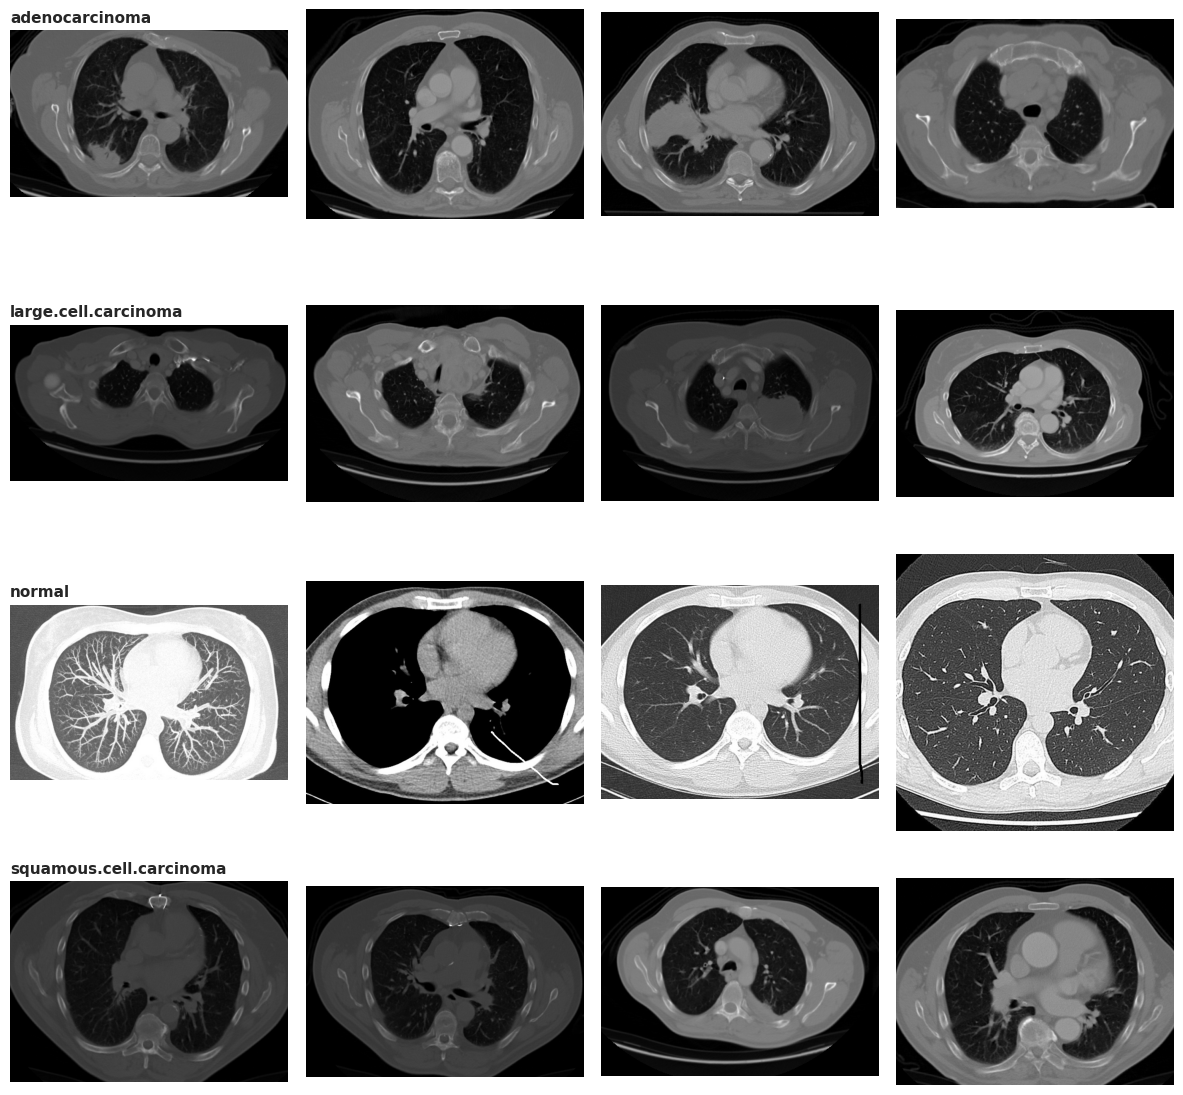

In [ ]:
# Rejilla de muestras: 4 imagenes por clase
fig, axes = plt.subplots(N_CLASES, 4, figsize=(12, 3 * N_CLASES))
for i, clase in enumerate(CLASES):
    muestras = df[df["clase"] == clase].sample(4, random_state=SEED)
    for j, (_, fila) in enumerate(muestras.iterrows()):
        with Image.open(fila["ruta"]) as im:
            axes[i, j].imshow(im.convert("RGB"))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(clase, loc="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

---
## Bloque 3 — 4.2.3 Preprocesado y particionado

Primero se divide el conjunto y después se preprocesa. El conjunto de test se aparta en este punto
y no se vuelve a usar hasta el Bloque 7. Todo lo que se ajusta (arquitectura, hiperparámetros,
número de épocas) se decide solo con los datos de `trainval`.

Con 41 imágenes de test, cada error equivale a 2,4 puntos de exactitud global, y con 7 imágenes de
la clase `normal` su *recall* solo puede tomar 8 valores.

In [ ]:
df_trainval, df_test = train_test_split(
    df, test_size=TEST_FRAC, stratify=df["y"], random_state=SEED, shuffle=True
)
df_train, df_val = train_test_split(
    df_trainval, test_size=VAL_FRAC / (1 - TEST_FRAC),
    stratify=df_trainval["y"], random_state=SEED, shuffle=True
)

print(f"Train   : {len(df_train):3d}  {df_train['clase'].value_counts().to_dict()}")
print(f"Val     : {len(df_val):3d}  {df_val['clase'].value_counts().to_dict()}")
print(f"Test    : {len(df_test):3d}  {df_test['clase'].value_counts().to_dict()}")

# Comprobacion de seguridad: ninguna ruta compartida entre particiones
assert not (set(df_train.ruta) & set(df_test.ruta)), "Fuga de datos train/test"
assert not (set(df_val.ruta)   & set(df_test.ruta)), "Fuga de datos val/test"
print("\nSin solape entre particiones.")

Train   : 189  {'large.cell.carcinoma': 53, 'squamous.cell.carcinoma': 52, 'adenocarcinoma': 52, 'normal': 32}
Val     :  41  {'adenocarcinoma': 12, 'squamous.cell.carcinoma': 11, 'large.cell.carcinoma': 11, 'normal': 7}
Test    :  41  {'squamous.cell.carcinoma': 12, 'large.cell.carcinoma': 11, 'adenocarcinoma': 11, 'normal': 7}

Sin solape entre particiones.


### Control E0. Clasificador de metadatos sin anatomía

Un *Random Forest* entrenado solo con metadatos y estadísticos globales (tamaño, modo de color,
brillo medio, contraste e intensidad del borde), sin ningún píxel del pulmón, mide cuánta señal de
la clase está en la adquisición. Se evalúa con validación cruzada sobre `trainval`, sin las 41
imágenes de test. En la misma celda se repite el análisis de propiedades técnicas y de intensidad
del borde sin las imágenes de test.

**Nota.** La salida indica entre paréntesis el valor del primer cálculo, que se hizo con las 271
imágenes del piloto, incluidas las 41 de test. El valor válido es el obtenido sin ellas.

trainval: 230 imagenes  |  test excluido: 41
clase
adenocarcinoma             64
large.cell.carcinoma       64
normal                     39
squamous.cell.carcinoma    63 

=== 1) PROPIEDADES TECNICAS (trainval) ===
Resoluciones distintas: 224
Resolucion mas frecuente: (np.int64(450), np.int64(329)) -> 2 imagenes
Modos de color: {'RGBA': 217, 'RGB': 13} 

=== 2) BORDE (df_dedup sin test: 784 imagenes) ===
Proporcion con borde oscuro (%):
clase
adenocarcinoma             90.2
large.cell.carcinoma       93.1
normal                     28.2
squamous.cell.carcinoma    95.1

Mediana de intensidad del borde:
clase
adenocarcinoma              4.0
large.cell.carcinoma        5.0
normal                     69.0
squamous.cell.carcinoma     1.0 



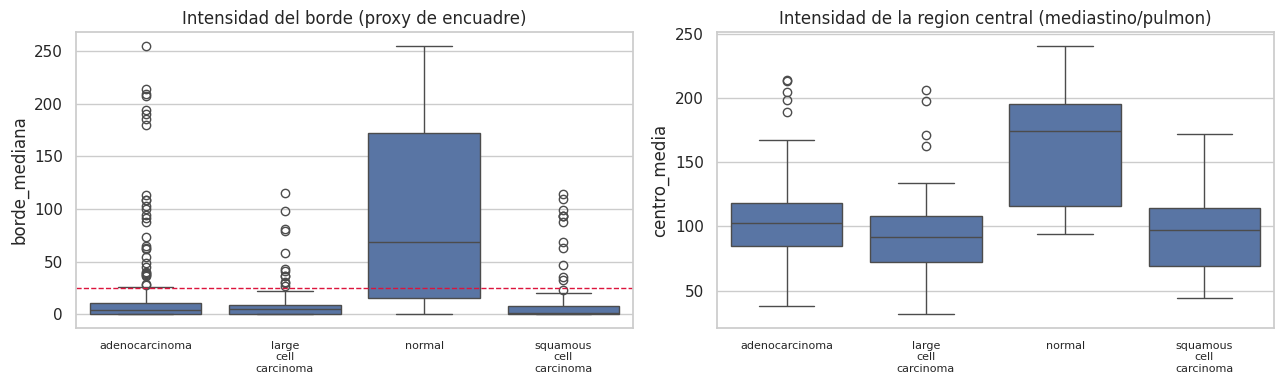

=== 3) E0 SOBRE TRAINVAL ===
Exactitud balanceada : 0.618   (antes 0.627 con 271)
Exactitud simple     : 0.583   (antes 0.594 con 271)
Azar con 4 clases   : 0.250

Matriz de confusion (filas = real, columnas = predicha):
                         adenocarcinoma  large.cell.carcinoma  normal  squamous.cell.carcinoma
adenocarcinoma                       32                    13       3                       16
large.cell.carcinoma                 12                    35       1                       16
normal                                1                     1      37                        0
squamous.cell.carcinoma              17                    16       0                       30

Recall de 'normal'   : 0.949 (37 de 39)   (antes 0.935, 43 de 46)

Recall por clase:
  adenocarcinoma             0.500  (32 de 64)
  large.cell.carcinoma       0.547  (35 de 64)
  normal                     0.949  (37 de 39)
  squamous.cell.carcinoma    0.476  (30 de 63)

Variables con mas peso:
p95  

In [ ]:
# =====================================================================
# Control E0 y analisis exploratorio SIN el conjunto de test
# Se ejecuta DESPUES del particionado. Las 41 imagenes de test no
# intervienen en ningun calculo de esta celda.
# =====================================================================
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import balanced_accuracy_score, confusion_matrix

rutas_test = set(df_test["ruta"])
assert len(rutas_test) == 41, "El test deberia tener 41 imagenes"
assert not (set(df_trainval["ruta"]) & rutas_test), "Fuga trainval/test"
print(f"trainval: {len(df_trainval)} imagenes  |  test excluido: {len(rutas_test)}")
print(df_trainval["clase"].value_counts().reindex(CLASES).to_string(), "\n")

# ---------------------------------------------------------------------
# 1) Propiedades tecnicas -> solo trainval
# ---------------------------------------------------------------------
props = []
for _, fila in df_trainval.iterrows():
    with Image.open(fila["ruta"]) as im:
        w, h = im.size
        props.append({"ancho": w, "alto": h, "modo": im.mode})
df_props_tv = pd.DataFrame(props)
res_tv = df_props_tv.groupby(["ancho", "alto"]).size().sort_values(ascending=False)

print("=== 1) PROPIEDADES TECNICAS (trainval) ===")
print("Resoluciones distintas:", len(res_tv))
print("Resolucion mas frecuente:", res_tv.index[0], "->", res_tv.iloc[0], "imagenes")
print("Modos de color:", df_props_tv["modo"].value_counts().to_dict(), "\n")

# ---------------------------------------------------------------------
# 2) Borde oscuro e intensidad central
#    -> df_dedup SIN las 41 de test (se conserva el resto del dataset)
# ---------------------------------------------------------------------
df_borde = df_dedup[~df_dedup["ruta"].isin(rutas_test)].copy()

print("=== 2) BORDE (df_dedup sin test:", len(df_borde), "imagenes) ===")
print("Proporcion con borde oscuro (%):")
print((df_borde.groupby("clase")["borde_oscuro"].mean() * 100).round(1).to_string())
print("\nMediana de intensidad del borde:")
print(df_borde.groupby("clase")["borde_mediana"].median().round(1).to_string(), "\n")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df_borde, x="clase", y="borde_mediana", order=CLASES, ax=axes[0])
axes[0].axhline(25, color="crimson", ls="--", lw=1)
axes[0].set_title("Intensidad del borde (proxy de encuadre)")
sns.boxplot(data=df_borde, x="clase", y="centro_media", order=CLASES, ax=axes[1])
axes[1].set_title("Intensidad de la region central (mediastino/pulmon)")
for ax in axes:
    ax.set_xticks(range(len(CLASES)))
    ax.set_xticklabels([c.replace(".", "\n") for c in CLASES], fontsize=8)
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig("intensidad-borde.png", dpi=200, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------------
# 3) E0: Random Forest de metadatos -> solo trainval
# ---------------------------------------------------------------------
meta = []
for _, fila in df_trainval.iterrows():
    with Image.open(fila["ruta"]) as im:
        w, h = im.size
        modo = im.mode
        g = np.asarray(im.convert("L").resize((256, 256)), dtype=np.float32)
    borde = np.concatenate([g[:20, :].ravel(), g[-20:, :].ravel(),
                            g[:, :20].ravel(), g[:, -20:].ravel()])
    meta.append({
        "ancho": w, "alto": h, "aspecto": w / h, "n_pixeles": w * h,
        "es_rgba": int(modo == "RGBA"),
        "media": g.mean(), "std": g.std(),
        "p05": np.percentile(g, 5), "p95": np.percentile(g, 95),
        "borde_mediana": np.median(borde), "borde_std": borde.std(),
    })

X_tv = pd.DataFrame(meta)
y_tv = df_trainval["y"].values

skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=400, random_state=SEED, class_weight="balanced")
y_hat_tv = cross_val_predict(rf, X_tv, y_tv, cv=skf5)

ba_tv = balanced_accuracy_score(y_tv, y_hat_tv)
acc_tv = (y_hat_tv == y_tv).mean()
cm_tv = confusion_matrix(y_tv, y_hat_tv)
i_norm = CLASES.index("normal")

print("=== 3) E0 SOBRE TRAINVAL ===")
print(f"Exactitud balanceada : {ba_tv:.3f}   (antes 0.627 con 271)")
print(f"Exactitud simple     : {acc_tv:.3f}   (antes 0.594 con 271)")
print(f"Azar con {N_CLASES} clases   : {1/N_CLASES:.3f}\n")
print("Matriz de confusion (filas = real, columnas = predicha):")
print(pd.DataFrame(cm_tv, index=CLASES, columns=CLASES).to_string())
print(f"\nRecall de 'normal'   : {cm_tv[i_norm, i_norm] / cm_tv[i_norm].sum():.3f} "
      f"({cm_tv[i_norm, i_norm]} de {cm_tv[i_norm].sum()})   (antes 0.935, 43 de 46)")
print("\nRecall por clase:")
for k, c in enumerate(CLASES):
    print(f"  {c:26s} {cm_tv[k, k] / cm_tv[k].sum():.3f}  ({cm_tv[k, k]} de {cm_tv[k].sum()})")

rf.fit(X_tv, y_tv)
imp_tv = pd.Series(rf.feature_importances_, index=X_tv.columns).sort_values(ascending=False)
print("\nVariables con mas peso:")
print(imp_tv.head(6).round(3).to_string())

In [ ]:
from tensorflow.keras.applications.resnet50 import preprocess_input as prep_resnet

def _leer_imagen(ruta, etiqueta):
    img = tf.io.read_file(ruta)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE, method="bilinear")
    img = tf.cast(img, tf.float32)            # rango [0, 255]
    return img, etiqueta

def normalizar(x, modo):
    # 'scratch' -> escalado simple a [0,1]
    # 'resnet'  -> preprocesado especifico de ImageNet/ResNet50 (media BGR)
    if modo == "scratch":
        return x / 255.0
    return prep_resnet(x)

def crear_dataset(dframe, modo, aumentar=False, mezclar=False, batch=BATCH_SIZE, aug_fn=None):
    ds = tf.data.Dataset.from_tensor_slices(
        (dframe["ruta"].values, dframe["y"].values.astype("int32"))
    )
    if mezclar:
        ds = ds.shuffle(len(dframe), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(_leer_imagen, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch)
    if aumentar and aug_fn is not None:
        ds = ds.map(lambda x, y: (aug_fn(x, training=True), y),
                    num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda x, y: (normalizar(x, modo), y),
                num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

print("Funciones de pipeline definidas.")

Funciones de pipeline definidas.


---
## Bloque 4 — 4.2.4 Aumentación de datos

La aumentación se aplica solo al conjunto de entrenamiento. Aplicarla a validación o test alteraría
la estimación del error.

El volteo horizontal está desactivado (`USAR_FLIP_HORIZONTAL = False`). En una CT de tórax el
corazón está a la izquierda y los lóbulos no son simétricos, de modo que una imagen volteada
representa una anatomía imposible (*situs inversus*).

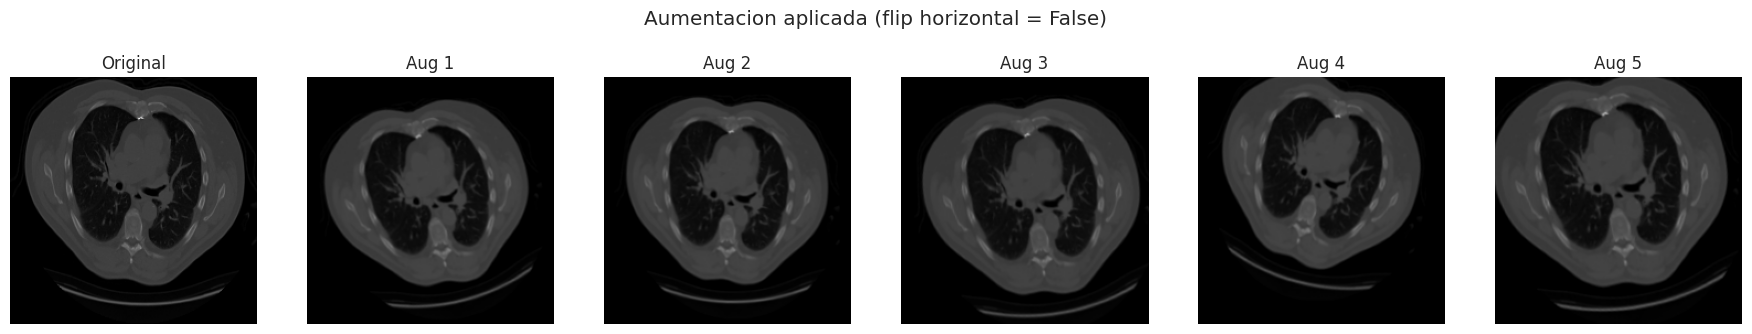

In [ ]:
capas_aug = [
    layers.RandomRotation(0.06, fill_mode="constant", fill_value=0.0),   # +/- ~21 grados
    layers.RandomZoom(0.10, fill_mode="constant", fill_value=0.0),
    layers.RandomTranslation(0.06, 0.06, fill_mode="constant", fill_value=0.0),
    layers.RandomContrast(0.10),
]
if USAR_FLIP_HORIZONTAL:
    capas_aug.insert(0, layers.RandomFlip("horizontal"))

aumentador = keras.Sequential(capas_aug, name="aumentacion")

# Visualizacion del efecto sobre una imagen concreta
ruta_demo = df_train.iloc[0]["ruta"]
img_demo, _ = _leer_imagen(tf.constant(ruta_demo), tf.constant(0))
lote_demo = tf.expand_dims(img_demo, 0)

fig, axes = plt.subplots(1, 6, figsize=(18, 3.2))
axes[0].imshow(img_demo.numpy().astype("uint8")); axes[0].set_title("Original"); axes[0].axis("off")
for k in range(1, 6):
    aug = aumentador(lote_demo, training=True)[0].numpy()
    axes[k].imshow(np.clip(aug, 0, 255).astype("uint8"))
    axes[k].set_title(f"Aug {k}"); axes[k].axis("off")
plt.suptitle(f"Aumentacion aplicada (flip horizontal = {USAR_FLIP_HORIZONTAL})", y=1.04)
plt.tight_layout(); plt.show()

---
## Bloque 5 — 4.3 Arquitectura del modelo

Se comparan dos estrategias, una CNN entrenada desde cero (Modelo A) y ResNet50 con *transfer
learning* (Modelo B), y se cuentan sus parámetros. En la segunda fase del entrenamiento del Modelo B
se descongela el bloque `conv5` y el ajuste fino se hace con una tasa de aprendizaje de 1e-5.

La red se construye con `input_tensor` para que el grafo quede plano (sin modelos anidados), lo que
permite acceder a la última capa convolucional desde Grad-CAM en el Bloque 8.

In [ ]:
def construir_cnn_scratch(n_clases=N_CLASES):
    entrada = keras.Input(shape=(*IMG_SIZE, 3), name="entrada")
    x = entrada
    for filtros in (32, 64, 128):
        x = layers.Conv2D(filtros, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Conv2D(filtros, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    salida = layers.Dense(n_clases, activation="softmax", name="salida")(x)
    return keras.Model(entrada, salida, name="cnn_scratch")


def construir_resnet_transfer(n_clases=N_CLASES, dropout=0.4):
    entrada = keras.Input(shape=(*IMG_SIZE, 3), name="entrada")
    base = keras.applications.ResNet50(
        include_top=False, weights="imagenet", input_tensor=entrada
    )
    base.trainable = False
    x = layers.GlobalAveragePooling2D(name="gap")(base.output)
    x = layers.Dropout(dropout)(x)
    salida = layers.Dense(n_clases, activation="softmax", name="salida")(x)
    modelo = keras.Model(entrada, salida, name="resnet50_transfer")
    modelo._nombre_base = "conv5_block3_out"   # capa conv final, la usara Grad-CAM
    return modelo


m = construir_resnet_transfer()
entrenables = sum(int(np.prod(w.shape)) for w in m.trainable_weights)
totales     = m.count_params()
print(f"ResNet50 transfer -> parametros totales: {totales:,} | entrenables: {entrenables:,}")

m2 = construir_cnn_scratch()
print(f"CNN desde cero    -> parametros totales: {m2.count_params():,} (todos entrenables)")
del m, m2

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
ResNet50 transfer -> parametros totales: 23,595,908 | entrenables: 8,196
CNN desde cero    -> parametros totales: 305,828 (todos entrenables)


---
## Bloque 6 — 4.4.1 Configuración del entrenamiento y comparativa inicial

Optimizador Adam, pérdida `sparse_categorical_crossentropy` y *early stopping* sobre `val_loss` con
restauración de los mejores pesos, junto con la reducción de la tasa de aprendizaje cuando la
pérdida de validación deja de mejorar.

In [ ]:
def callbacks_estandar(paciencia=10):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia,
                                      restore_best_weights=True, verbose=0),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                          patience=4, min_lr=1e-7, verbose=0),
    ]

def pesos_de_clase(dframe):
    y = dframe["y"].values
    pesos = compute_class_weight("balanced", classes=np.arange(N_CLASES), y=y)
    return {i: float(w) for i, w in enumerate(pesos)}


def entrenar_scratch(df_tr, df_va, epochs=EPOCHS_CABEZA, verbose=0):
    global EPOCHS_CABEZA
    tf.keras.backend.clear_session(); tf.random.set_seed(SEED)
    modelo = construir_cnn_scratch()
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    hist = modelo.fit(
        crear_dataset(df_tr, "scratch", aumentar=True, mezclar=True, aug_fn=aumentador),
        validation_data=crear_dataset(df_va, "scratch"),
        epochs=epochs, callbacks=callbacks_estandar(), class_weight=pesos_de_clase(df_tr),
        verbose=verbose,
    )
    return modelo, hist


def entrenar_transfer(df_tr, df_va, epochs_cabeza=EPOCHS_CABEZA,
                      epochs_ft=EPOCHS_FINETUNE, verbose=0):
    global EPOCHS_CABEZA, EPOCHS_FINETUNE
    tf.keras.backend.clear_session(); tf.random.set_seed(SEED)
    modelo = construir_resnet_transfer()
    ds_tr = crear_dataset(df_tr, "resnet", aumentar=True, mezclar=True, aug_fn=aumentador)
    ds_va = crear_dataset(df_va, "resnet")
    pesos = pesos_de_clase(df_tr)

    # Fase 1: solo la cabeza
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h1 = modelo.fit(ds_tr, validation_data=ds_va, epochs=epochs_cabeza,
                    callbacks=callbacks_estandar(), class_weight=pesos, verbose=verbose)

    # Fase 2: fine-tuning del ultimo bloque convolucional con lr muy baja
    for capa in modelo.layers:
        if capa.name.startswith("conv5"):
            if not isinstance(capa, layers.BatchNormalization):
                capa.trainable = True
    modelo.compile(optimizer=keras.optimizers.Adam(1e-5),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h2 = modelo.fit(ds_tr, validation_data=ds_va, epochs=epochs_ft,
                    callbacks=callbacks_estandar(paciencia=8), class_weight=pesos, verbose=verbose)

    hist = {k: h1.history.get(k, []) + h2.history.get(k, [])
            for k in ("loss", "val_loss", "accuracy", "val_accuracy")}
    hist["corte_finetune"] = len(h1.history["loss"])
    return modelo, hist

In [ ]:
print("Entrenando Modelo A (CNN desde cero)...")
modelo_a, hist_a = entrenar_scratch(df_train, df_val)
print(f"  mejor val_accuracy: {max(hist_a.history['val_accuracy']):.3f}")

print("\nEntrenando Modelo B (ResNet50 transfer + fine-tuning)...")
modelo_b, hist_b = entrenar_transfer(df_train, df_val)
print(f"  mejor val_accuracy: {max(hist_b['val_accuracy']):.3f}")

Entrenando Modelo A (CNN desde cero)...
  mejor val_accuracy: 0.488

Entrenando Modelo B (ResNet50 transfer + fine-tuning)...
  mejor val_accuracy: 0.878


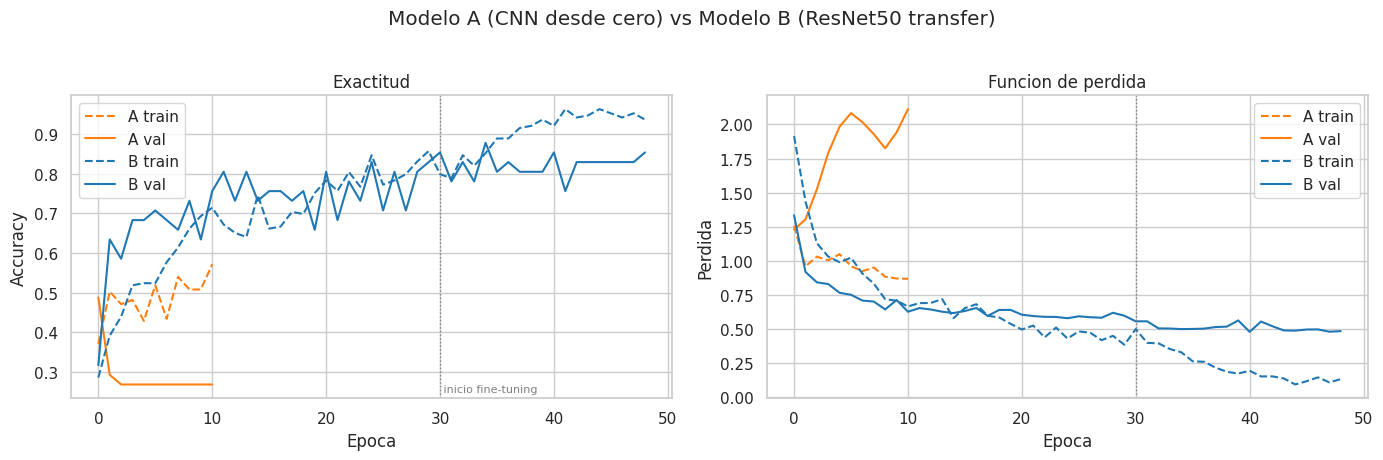

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(hist_a.history["accuracy"],     label="A train", ls="--", color="tab:orange")
axes[0].plot(hist_a.history["val_accuracy"], label="A val",   color="tab:orange")
axes[0].plot(hist_b["accuracy"],             label="B train", ls="--", color="tab:blue")
axes[0].plot(hist_b["val_accuracy"],         label="B val",   color="tab:blue")
axes[0].axvline(hist_b["corte_finetune"], color="gray", ls=":", lw=1)
axes[0].text(hist_b["corte_finetune"], 0.25, " inicio fine-tuning", fontsize=8, color="gray")
axes[0].set_xlabel("Epoca"); axes[0].set_ylabel("Accuracy"); axes[0].legend()
axes[0].set_title("Exactitud")

axes[1].plot(hist_a.history["loss"],     label="A train", ls="--", color="tab:orange")
axes[1].plot(hist_a.history["val_loss"], label="A val",   color="tab:orange")
axes[1].plot(hist_b["loss"],             label="B train", ls="--", color="tab:blue")
axes[1].plot(hist_b["val_loss"],         label="B val",   color="tab:blue")
axes[1].axvline(hist_b["corte_finetune"], color="gray", ls=":", lw=1)
axes[1].set_xlabel("Epoca"); axes[1].set_ylabel("Perdida"); axes[1].legend()
axes[1].set_title("Funcion de perdida")

plt.suptitle("Modelo A (CNN desde cero) vs Modelo B (ResNet50 transfer)", y=1.02)
plt.tight_layout(); plt.show()

En las curvas, la separación entre la línea discontinua (entrenamiento) y la continua (validación)
indica el grado de sobreajuste de cada modelo.

---
## Bloque 7 — 4.4.2 Estrategia de validación: validación cruzada estratificada

Una única partición de 41 imágenes de validación no permite distinguir una diferencia real de
ruido de muestreo. Se repite el entrenamiento del Modelo B en `N_FOLDS` particiones y se presenta la
**media ± desviación típica**.

*Esta celda tarda varios minutos (5 entrenamientos completos).*

In [ ]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
X_idx = np.arange(len(df_trainval))
y_cv  = df_trainval["y"].values

resultados_cv = []
for fold, (idx_tr, idx_va) in enumerate(skf.split(X_idx, y_cv), start=1):
    d_tr = df_trainval.iloc[idx_tr]
    d_va = df_trainval.iloc[idx_va]
    modelo_f, _ = entrenar_transfer(d_tr, d_va, verbose=0)
    perdida, acc = modelo_f.evaluate(crear_dataset(d_va, "resnet"), verbose=0)
    resultados_cv.append({"fold": fold, "val_accuracy": acc, "val_loss": perdida})
    print(f"Fold {fold}/{N_FOLDS}  ->  accuracy = {acc:.4f}   loss = {perdida:.4f}")
    del modelo_f
    tf.keras.backend.clear_session()

df_cv = pd.DataFrame(resultados_cv)
media, desv = df_cv["val_accuracy"].mean(), df_cv["val_accuracy"].std()
print(f"\nAccuracy en validacion cruzada: {media:.4f} +/- {desv:.4f}")
print(f"Rango observado: [{df_cv['val_accuracy'].min():.4f}, {df_cv['val_accuracy'].max():.4f}]")

Fold 1/5  ->  accuracy = 0.8696   loss = 0.3299
Fold 2/5  ->  accuracy = 0.8043   loss = 0.5977
Fold 3/5  ->  accuracy = 0.8261   loss = 0.6406
Fold 4/5  ->  accuracy = 0.8261   loss = 0.6098
Fold 5/5  ->  accuracy = 0.6957   loss = 0.6349

Accuracy en validacion cruzada: 0.8043 +/- 0.0652
Rango observado: [0.6957, 0.8696]


La interpretación de la validación cruzada y de la matriz de confusión se recoge en las
Secciones 5.3.3 y 5.3.4 de la memoria.

                         precision    recall  f1-score   support

         adenocarcinoma      0.833     0.455     0.588        11
   large.cell.carcinoma      0.647     1.000     0.786        11
                 normal      0.778     1.000     0.875         7
squamous.cell.carcinoma      0.778     0.583     0.667        12

               accuracy                          0.732        41
              macro avg      0.759     0.759     0.729        41
           weighted avg      0.758     0.732     0.713        41



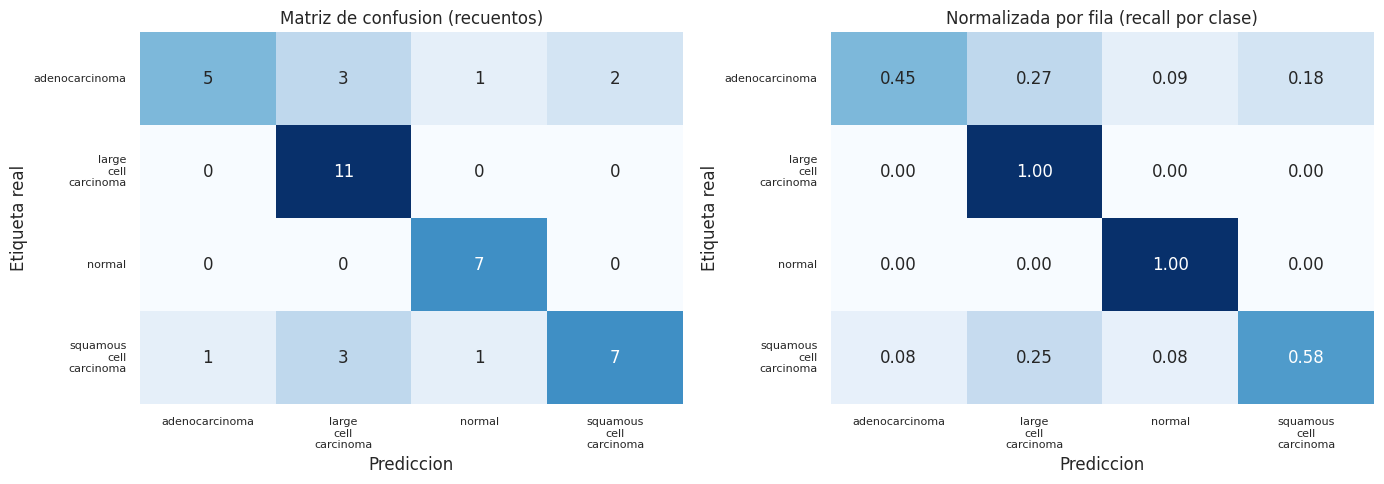


Atencion: el test tiene solo 41 imagenes (~10 por clase). Cada error vale 2.4 puntos de exactitud.


In [ ]:
# Evaluacion final sobre el conjunto de test bloqueado, con el Modelo B del Bloque 6
y_prob = modelo_b.predict(crear_dataset(df_test, "resnet"), verbose=0)
y_pred = y_prob.argmax(axis=1)
y_true = df_test["y"].values

print(classification_report(y_true, y_pred, target_names=CLASES, digits=3, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=range(N_CLASES))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=CLASES, yticklabels=CLASES, ax=axes[0])
axes[0].set_xlabel("Prediccion"); axes[0].set_ylabel("Etiqueta real")
axes[0].set_title("Matriz de confusion (recuentos)")

cm_norm = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", cbar=False, vmin=0, vmax=1,
            xticklabels=CLASES, yticklabels=CLASES, ax=axes[1])
axes[1].set_xlabel("Prediccion"); axes[1].set_ylabel("Etiqueta real")
axes[1].set_title("Normalizada por fila (recall por clase)")

for ax in axes:
    ax.set_xticklabels([c.replace(".", "\n") for c in CLASES], fontsize=8, rotation=0)
    ax.set_yticklabels([c.replace(".", "\n") for c in CLASES], fontsize=8, rotation=0)
plt.tight_layout(); plt.show()

print(f"\nAtencion: el test tiene solo {len(df_test)} imagenes "
      f"(~{len(df_test)//N_CLASES} por clase). Cada error vale "
      f"{100/len(df_test):.1f} puntos de exactitud.")

---
## Bloque 8 — 4.5 Técnicas de explicabilidad

### 4.5.1 Selección y justificación

- **Grad-CAM.** Específico de CNN, usa los gradientes de la clase predicha respecto al último mapa
  de características. Es rápido (una pasada hacia delante y otra hacia atrás) y determinista, pero
  su resolución espacial es baja (7×7 en ResNet50) y solo se aplica a arquitecturas convolucionales.
- **LIME.** Agnóstico al modelo, aproxima localmente la frontera de decisión con un modelo lineal
  sobre superpíxeles. Su coste es alto y el resultado es estocástico (dos ejecuciones pueden diferir).

Las dos técnicas se comparan de forma cualitativa en las imágenes analizadas con ambas.

In [ ]:
# ---------- 4.5.2 Grad-CAM ----------
def grad_cam(modelo, imagen_lote, indice_clase=None, nombre_capa=None):
    # imagen_lote: tensor (1, H, W, 3) ya preprocesado para el modelo
    nombre_capa = nombre_capa or getattr(modelo, "_nombre_base", "conv5_block3_out")
    capa_conv = modelo.get_layer(nombre_capa)
    modelo_grad = keras.Model(modelo.inputs, [capa_conv.output, modelo.output])

    with tf.GradientTape() as cinta:
        mapas, predicciones = modelo_grad(imagen_lote, training=False)
        if indice_clase is None:
            indice_clase = int(tf.argmax(predicciones[0]))
        score = predicciones[:, indice_clase]

    grads = cinta.gradient(score, mapas)
    pesos = tf.reduce_mean(grads, axis=(0, 1, 2))           # importancia por canal
    mapa = tf.reduce_sum(mapas[0] * pesos, axis=-1)         # combinacion ponderada
    mapa = tf.nn.relu(mapa)                                 # solo evidencia a favor
    mapa = mapa / (tf.reduce_max(mapa) + keras.backend.epsilon())
    return mapa.numpy(), indice_clase, predicciones.numpy()[0]


def superponer(mapa, imagen_rgb, alpha=0.45, cmap="jet"):
    import matplotlib.cm as cm
    mapa_r = np.array(Image.fromarray((mapa * 255).astype("uint8")).resize(
        (imagen_rgb.shape[1], imagen_rgb.shape[0]), Image.BILINEAR)) / 255.0
    color = cm.get_cmap(cmap)(mapa_r)[..., :3] * 255
    return np.clip(imagen_rgb * (1 - alpha) + color * alpha, 0, 255).astype("uint8")

print("Grad-CAM listo.")

Grad-CAM listo.


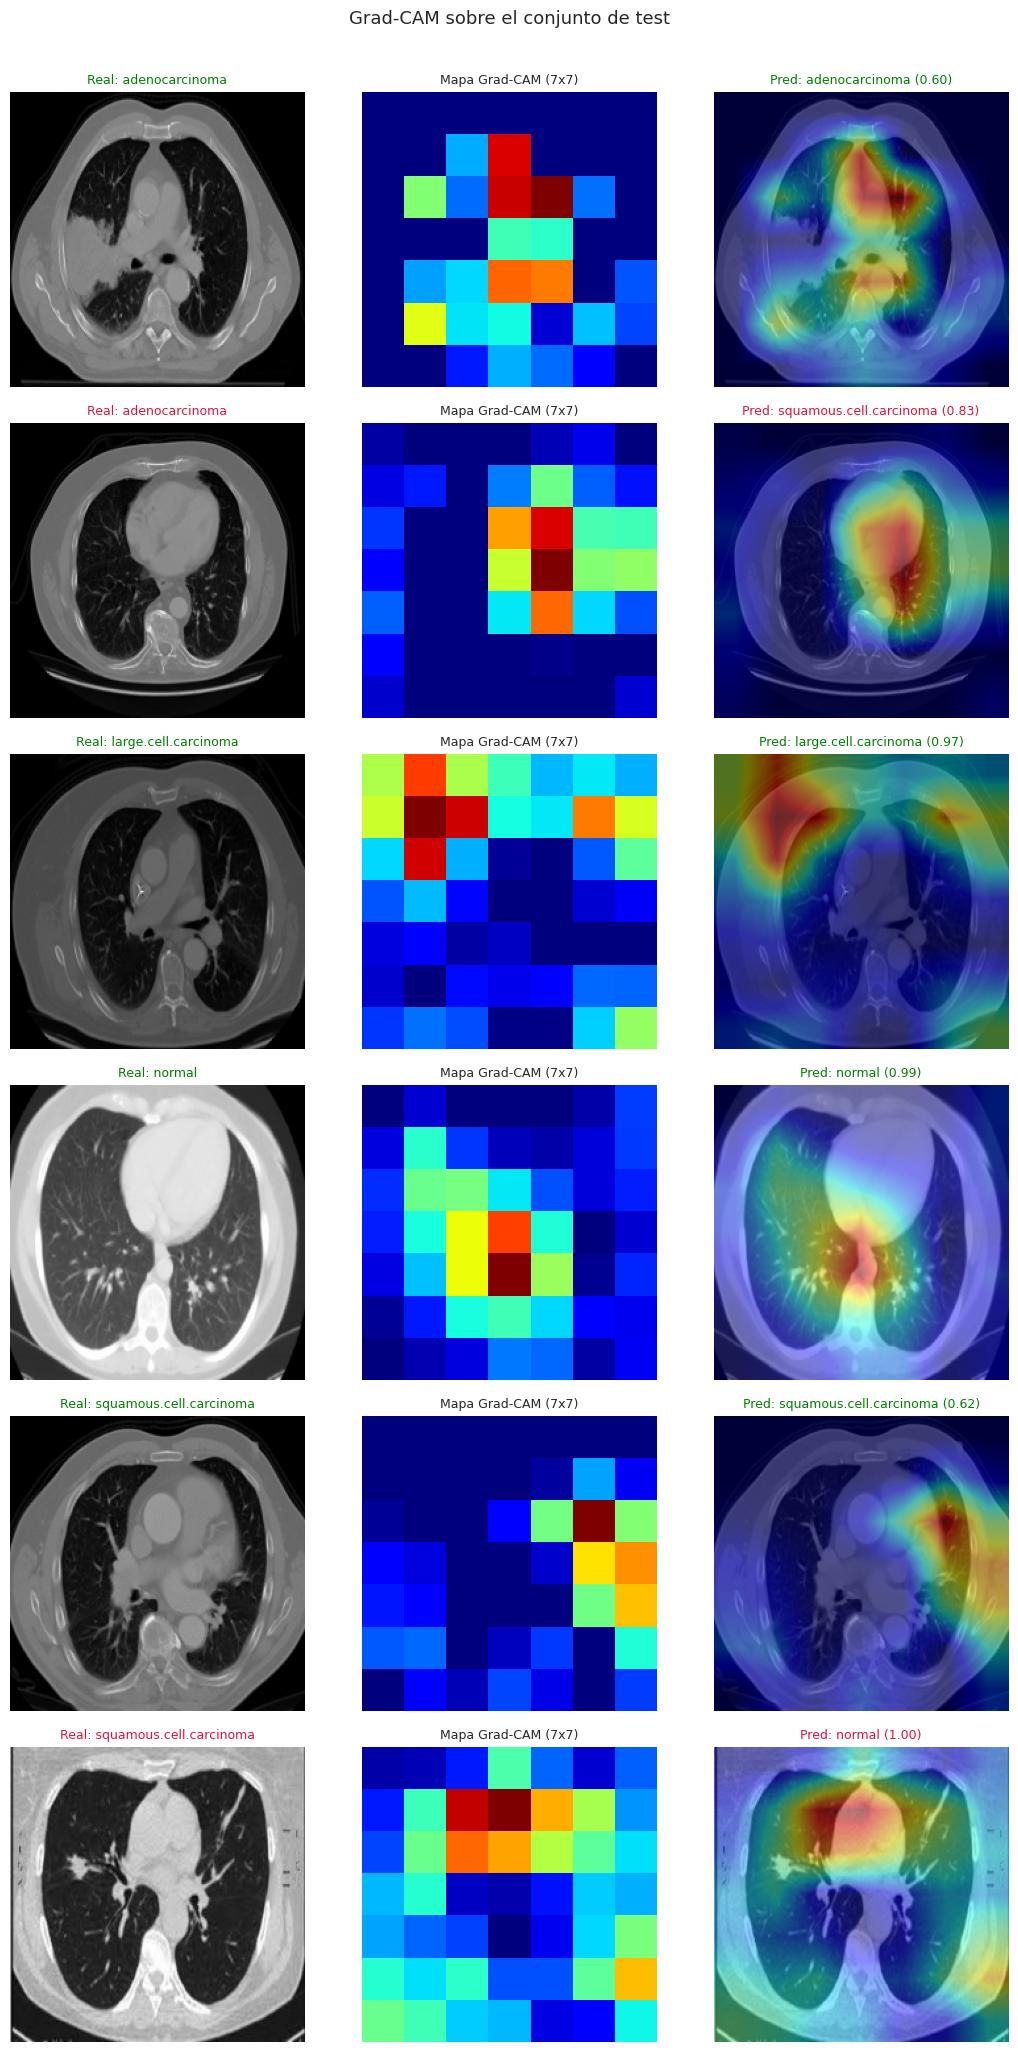

In [ ]:
# Visualizacion: un acierto y un fallo por clase (si existen)
seleccion = []
for c in range(N_CLASES):
    idx_clase = np.where(y_true == c)[0]
    aciertos = idx_clase[y_pred[idx_clase] == c]
    fallos   = idx_clase[y_pred[idx_clase] != c]
    if len(aciertos): seleccion.append((aciertos[0], True))
    if len(fallos):   seleccion.append((fallos[0], False))

filas = len(seleccion)
fig, axes = plt.subplots(filas, 3, figsize=(11, 3.4 * filas))
if filas == 1:
    axes = axes[np.newaxis, :]

for f, (i, es_acierto) in enumerate(seleccion):
    fila = df_test.iloc[i]
    img_bruta, _ = _leer_imagen(tf.constant(fila["ruta"]), tf.constant(0))
    rgb = np.clip(img_bruta.numpy(), 0, 255).astype("uint8")
    lote = prep_resnet(tf.expand_dims(img_bruta, 0))

    mapa, idx_pred, probs = grad_cam(modelo_b, lote)
    conf = probs[idx_pred]

    axes[f, 0].imshow(rgb); axes[f, 0].axis("off")
    axes[f, 0].set_title(f"Real: {fila['clase']}", fontsize=9,
                         color="green" if es_acierto else "crimson")
    axes[f, 1].imshow(mapa, cmap="jet"); axes[f, 1].axis("off")
    axes[f, 1].set_title("Mapa Grad-CAM (7x7)", fontsize=9)
    axes[f, 2].imshow(superponer(mapa, rgb.astype(float))); axes[f, 2].axis("off")
    axes[f, 2].set_title(f"Pred: {CLASES[idx_pred]} ({conf:.2f})", fontsize=9,
                         color="green" if es_acierto else "crimson")

plt.suptitle("Grad-CAM sobre el conjunto de test", y=1.005, fontsize=13)
plt.tight_layout(); plt.show()

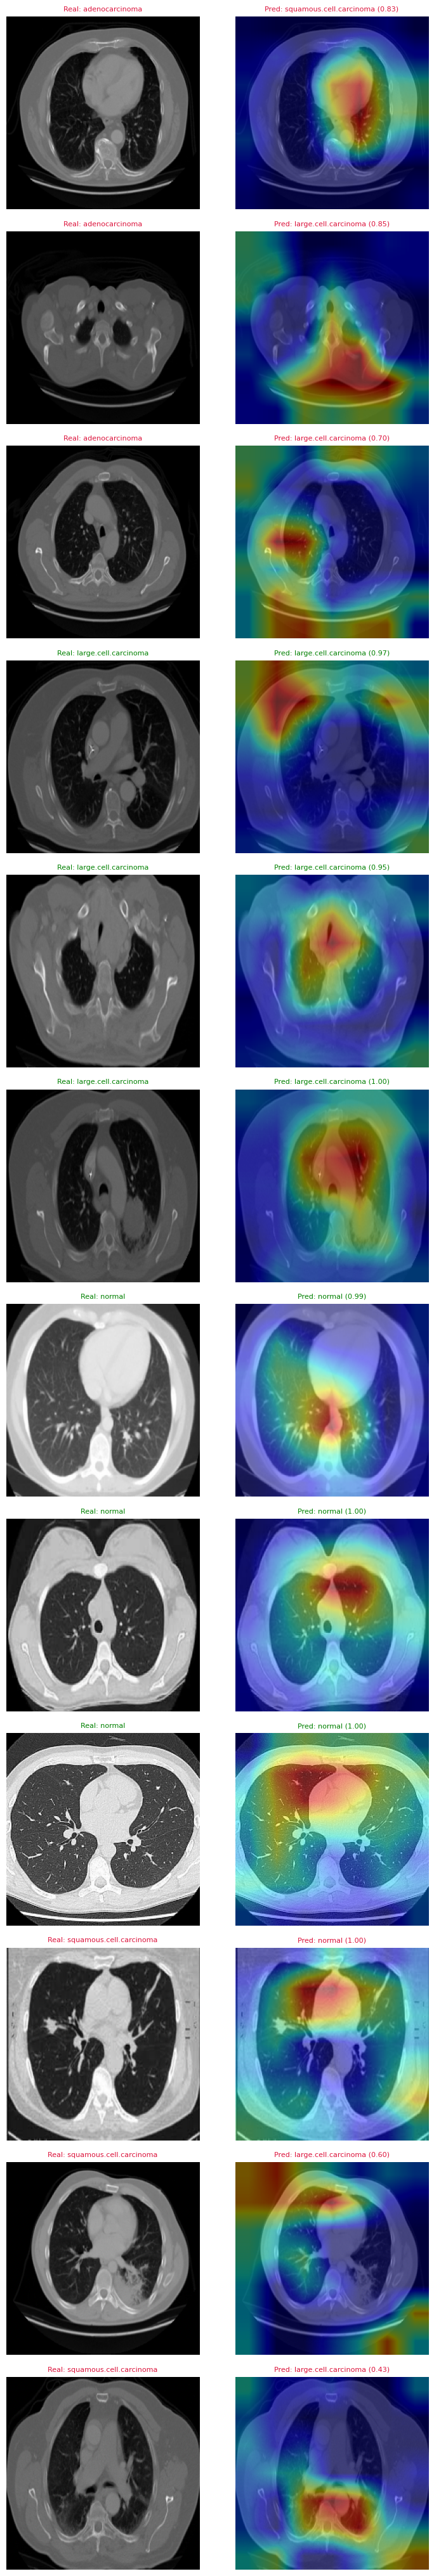

In [ ]:
# ---- Grad-CAM ampliado: 3 imagenes por clase ----
filas_sel = []
for c in range(N_CLASES):
    idx_c = np.where(y_true == c)[0]
    orden = sorted(idx_c, key=lambda i: y_pred[i] == c)  # fallos primero
    filas_sel += [(i, y_pred[i] == c) for i in orden[:3]]

fig, axes = plt.subplots(len(filas_sel), 2, figsize=(8, 3.4 * len(filas_sel)))
for f, (i, ok) in enumerate(filas_sel):
    fila = df_test.iloc[i]
    img, _ = _leer_imagen(tf.constant(fila["ruta"]), tf.constant(0))
    rgb = np.clip(img.numpy(), 0, 255).astype("uint8")
    mapa, idx_p, probs = grad_cam(modelo_b, prep_resnet(tf.expand_dims(img, 0)))
    axes[f, 0].imshow(rgb); axes[f, 0].axis("off")
    axes[f, 0].set_title(f"Real: {fila['clase']}", fontsize=8,
                         color="green" if ok else "crimson")
    axes[f, 1].imshow(superponer(mapa, rgb.astype(float))); axes[f, 1].axis("off")
    axes[f, 1].set_title(f"Pred: {CLASES[idx_p]} ({probs[idx_p]:.2f})", fontsize=8,
                         color="green" if ok else "crimson")
plt.tight_layout(); plt.show()

En cada mapa se comprueba si la zona marcada cae dentro del parénquima pulmonar o fuera de él
(pared torácica, camilla, aire de fondo o texto sobreimpreso del escáner). La interpretación de los
mapas se recoge en la Sección 5.4 de la memoria.

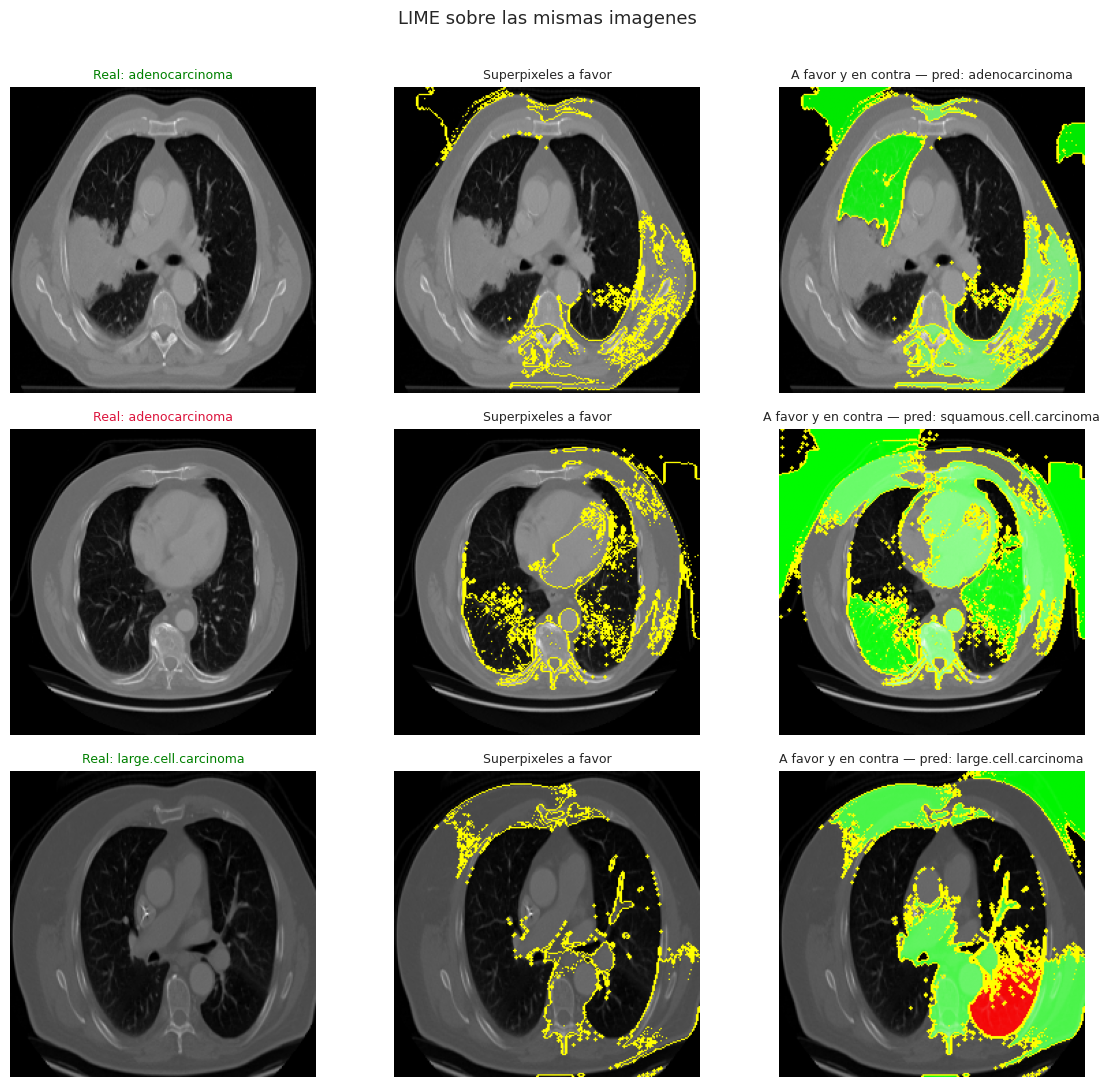

In [ ]:
# ---------- LIME ----------
from lime import lime_image
from skimage.segmentation import mark_boundaries

def predictor_lime(imagenes):
    # LIME entrega un array (N, H, W, 3) en rango [0, 255]; aplicamos aqui el preprocesado
    x = prep_resnet(tf.cast(tf.convert_to_tensor(imagenes), tf.float32))
    return modelo_b.predict(x, verbose=0)

explicador = lime_image.LimeImageExplainer(random_state=SEED)

n_ejemplos = min(3, len(seleccion))
fig, axes = plt.subplots(n_ejemplos, 3, figsize=(12, 3.6 * n_ejemplos))
if n_ejemplos == 1:
    axes = axes[np.newaxis, :]

for f in range(n_ejemplos):
    i, es_acierto = seleccion[f]
    fila = df_test.iloc[i]
    img_bruta, _ = _leer_imagen(tf.constant(fila["ruta"]), tf.constant(0))
    rgb = np.clip(img_bruta.numpy(), 0, 255).astype("uint8")

    exp = explicador.explain_instance(
        rgb.astype("double"), predictor_lime,
        top_labels=1, hide_color=0, num_samples=600, batch_size=16,
    )
    etiqueta = exp.top_labels[0]

    tmp_pos, mask_pos = exp.get_image_and_mask(
        etiqueta, positive_only=True, num_features=6, hide_rest=False)
    tmp_amb, mask_amb = exp.get_image_and_mask(
        etiqueta, positive_only=False, num_features=10, hide_rest=False)

    axes[f, 0].imshow(rgb); axes[f, 0].axis("off")
    axes[f, 0].set_title(f"Real: {fila['clase']}", fontsize=9,
                         color="green" if es_acierto else "crimson")
    axes[f, 1].imshow(mark_boundaries(tmp_pos / 255.0, mask_pos)); axes[f, 1].axis("off")
    axes[f, 1].set_title("Superpixeles a favor", fontsize=9)
    axes[f, 2].imshow(mark_boundaries(tmp_amb / 255.0, mask_amb)); axes[f, 2].axis("off")
    axes[f, 2].set_title(f"A favor y en contra — pred: {CLASES[etiqueta]}", fontsize=9)

plt.suptitle("LIME sobre las mismas imagenes", y=1.005, fontsize=13)
plt.tight_layout(); plt.show()

LIME se aplica a tres de las imágenes analizadas con Grad-CAM, con 600 perturbaciones y
semilla fija. El resultado depende de `num_samples`, y
la estabilidad de las explicaciones (por ejemplo, comparando 600 y 2000 perturbaciones) no se ha
medido en este piloto. La comparación con Grad-CAM se recoge en la Sección 5.4 de la memoria.

---
## Bloque 9 — Registro de resultados

La configuración y las métricas de la ejecución se guardan en un fichero JSON, con un fichero por
cada variante de prueba (con o sin volteo y distinto `N_POR_CLASE`).

In [ ]:
resumen = {
    "semilla": SEED,
    "n_por_clase": N_POR_CLASE,
    "n_total_piloto": len(df),
    "n_train": len(df_train), "n_val": len(df_val), "n_test": len(df_test),
    "clases": CLASES,
    "img_size": list(IMG_SIZE),
    "batch_size": BATCH_SIZE,
    "flip_horizontal": USAR_FLIP_HORIZONTAL,
    "dedup_perceptual": DEDUP_PERCEPTUAL,
    "imagenes_antes_dedup": int(n_inicial),
    "imagenes_tras_dedup": int(n_final),
    "cv_accuracy_media": float(media),
    "cv_accuracy_desv": float(desv),
    "cv_por_fold": df_cv.to_dict(orient="records"),
    "test_accuracy": float((y_pred == y_true).mean()),
    "test_report": classification_report(y_true, y_pred, target_names=CLASES,
                                         output_dict=True, zero_division=0),
}

nombre = f"resultados_piloto_n{N_POR_CLASE}_flip{int(USAR_FLIP_HORIZONTAL)}.json"
with open(nombre, "w", encoding="utf-8") as fh:
    json.dump(resumen, fh, indent=2, ensure_ascii=False)

print("Guardado en", nombre)
print(f"\nCV : {media:.4f} +/- {desv:.4f}")
print(f"Test: {resumen['test_accuracy']:.4f}")

Guardado en resultados_piloto_n75_flip0.json

CV : 0.8043 +/- 0.0652
Test: 0.7317
